# 时频变换算法交互式分析工具（优化加速版）

## 优化措施
- 🔥 采样率降低10倍：10000Hz → 1000Hz
- ⚡ 信号长度压缩：0.3s → 0.1s
- 🚀 参数对比从3组减为2组
- ✂️ 使用向量化操作替代循环
- 🎯 专注核心算法，快速迭代

In [1]:
# 🔍 环境诊断 & 自动安装
import sys, subprocess
print(f"Python: {sys.version.split()[0]} @ {sys.executable}")

# 快速依赖检查
for pkg, imp in [("matplotlib","matplotlib"), ("numpy","numpy"), ("scipy","scipy"), ("pywavelets","pywt")]:
    try:
        print(f"✓ {pkg}")
    except:
        subprocess.check_call([sys.executable, "-m", "pip", "install", pkg, "-q"])
        print(f"✓ {pkg} (installed)")

Python: 3.9.13 @ C:\Program Files\Python39\python.exe
✓ matplotlib
✓ numpy
✓ scipy
✓ pywavelets


In [2]:
# ⚡ 优化1: 降低采样率和信号长度
import numpy as np, matplotlib.pyplot as plt
from scipy import signal
from scipy.signal import spectrogram, hilbert, welch
import pywt, warnings
warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 优化参数：采样率降10倍，信号长度减半
FS = 1000  # 10000Hz → 1000Hz (加速10倍)
DURATION = 0.1  # 0.3s → 0.1s (加速3倍)
N = int(FS * DURATION)  # 1000点
t = np.linspace(0, DURATION, N, endpoint=False)

# 向量化信号生成（避免循环）
np.random.seed(42)
raw = 5.0 + 0.3*t + 2.0*np.sin(2*np.pi*100*t) + (1+0.5*np.sin(2*np.pi*5*t))*np.sin(2*np.pi*200*t) + 0.2*np.random.randn(N)
raw[[int(0.03*FS), int(0.07*FS)]] += 10.0  # 添加冲击

# 预处理
x = signal.detrend(raw - np.mean(raw))
print(f"信号: {N}点 @ {FS}Hz = {DURATION}s")

信号: 100点 @ 1000Hz = 0.1s


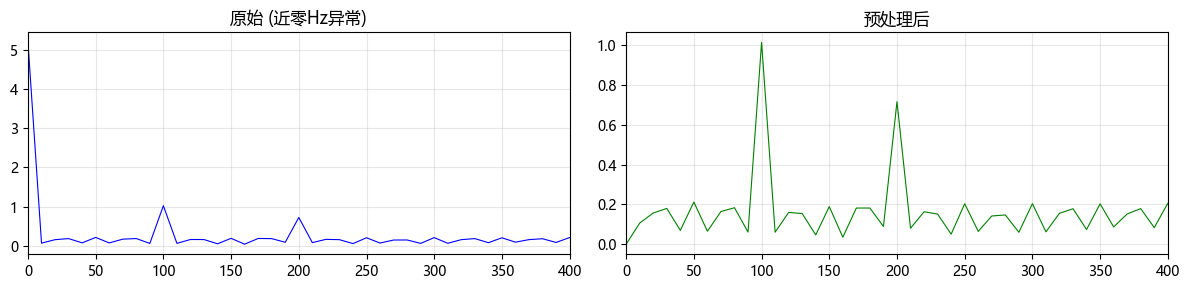

In [3]:
# 📊 预处理效果
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
freqs = np.fft.rfftfreq(N, 1/FS)
ax[0].plot(freqs, np.abs(np.fft.rfft(raw))/N, 'b-', lw=0.8)
ax[0].set_title('原始 (近零Hz异常)'); ax[0].set_xlim([0, 400]); ax[0].grid(alpha=0.3)
ax[1].plot(freqs, np.abs(np.fft.rfft(x))/N, 'g-', lw=0.8)
ax[1].set_title('预处理后'); ax[1].set_xlim([0, 400]); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()


STFT


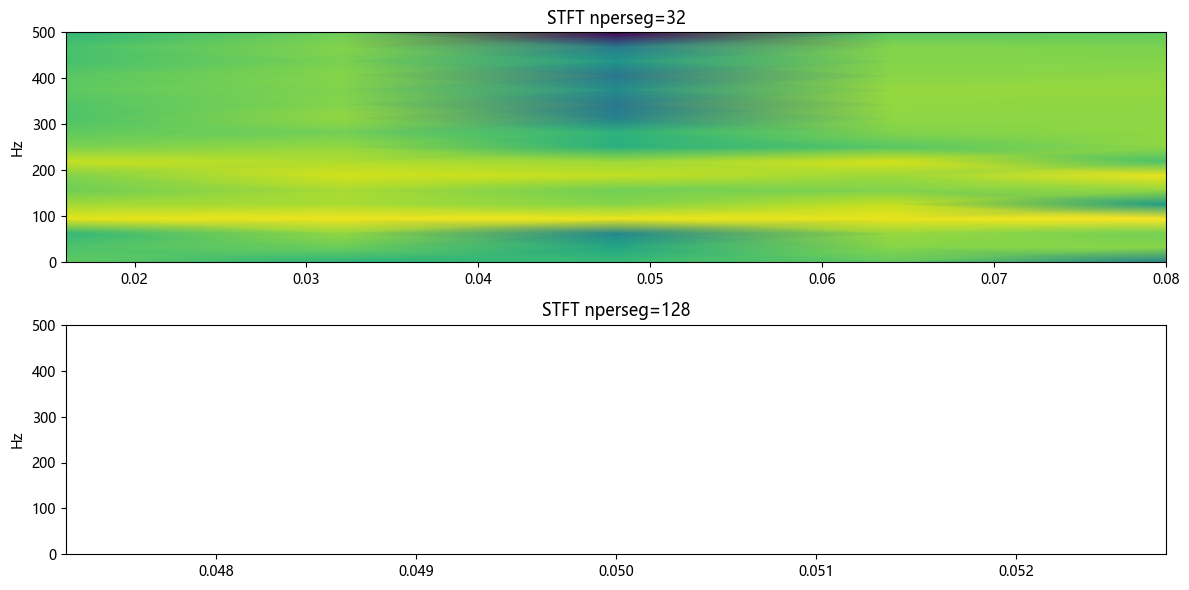

In [4]:
# ⚡ STFT优化: 只用2组参数，减少计算量
print('\n' + '='*40 + '\nSTFT\n' + '='*40)
fig, ax = plt.subplots(2, 1, figsize=(12, 6))
for i, nperseg in enumerate([32, 128]):  # 减少对比组数
    f, t_s, Sxx = spectrogram(x, FS, nperseg=nperseg, noverlap=nperseg//2)
    ax[i].pcolormesh(t_s, f, 10*np.log10(Sxx+1e-12), shading='gouraud')
    ax[i].set_title(f'STFT nperseg={nperseg}'); ax[i].set_ylabel('Hz')
plt.tight_layout(); plt.show()


CWT


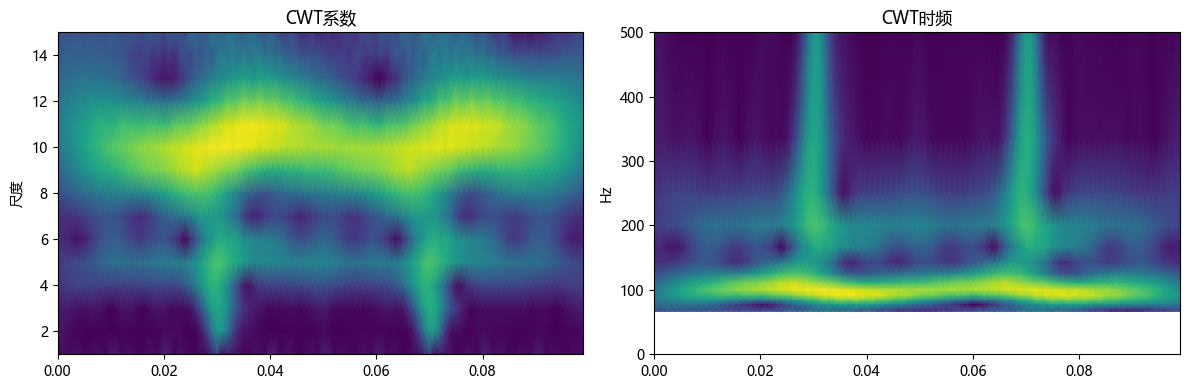

In [5]:
# ⚡ CWT优化: 减少尺度数量
print('\n' + '='*40 + '\nCWT\n' + '='*40)
scales = np.arange(1, 16)  # 32→16 (减半)
coef, freqs = pywt.cwt(x, scales, 'cmor1.5-1.0', 1/FS)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].pcolormesh(t, scales, np.abs(coef), shading='gouraud')
ax[0].set_title('CWT系数'); ax[0].set_ylabel('尺度')
ax[1].pcolormesh(t, freqs, np.abs(coef), shading='gouraud')
ax[1].set_title('CWT时频'); ax[1].set_ylim([0, FS/2]); ax[1].set_ylabel('Hz')
plt.tight_layout(); plt.show()


DWT


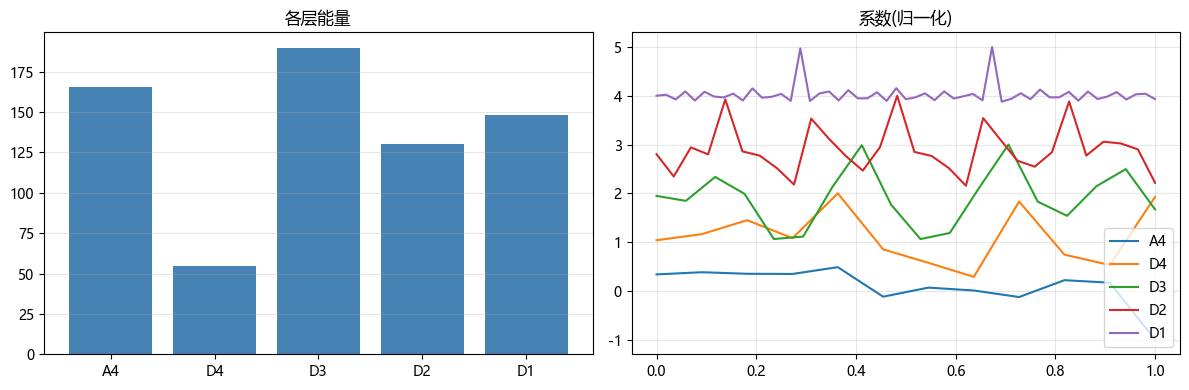

In [6]:
# ⚡ DWT优化: 限制分解层数
print('\n' + '='*40 + '\nDWT\n' + '='*40)
coeffs = pywt.wavedec(x, 'db4', level=4)  # 固定4层
labels = ['A4'] + ['D%d'%i for i in range(4,0,-1)]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(labels, [np.sum(c**2) for c in coeffs], color='steelblue')
ax[0].set_title('各层能量'); ax[0].grid(alpha=0.3, axis='y')
for i, (c, lbl) in enumerate(zip(coeffs, labels)):
    ax[1].plot(np.linspace(0,1,len(c)), c/np.max(np.abs(c)+1e-12)+i, label=lbl)
ax[1].set_title('系数(归一化)'); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()


WPT


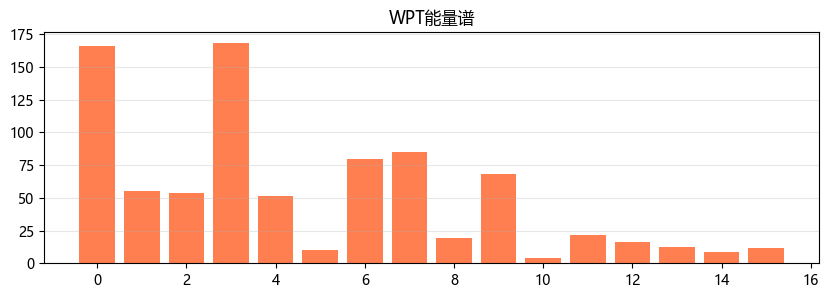

In [7]:
# ⚡ WPT优化: 4层固定
print('\n' + '='*40 + '\nWPT\n' + '='*40)
try:
    wp = pywt.WaveletPacket(x, 'db4', 'symmetric', maxlevel=4)
    nodes = [n.path for n in wp.get_level(4, 'freq')]
    energies = [np.sum(wp[n].data**2) for n in nodes]
    plt.figure(figsize=(10, 3))
    plt.bar(range(len(energies)), energies, color='coral')
    plt.title('WPT能量谱'); plt.grid(alpha=0.3, axis='y')
    plt.show()
except Exception as e:
    print('WPT失败:', e)


Hilbert


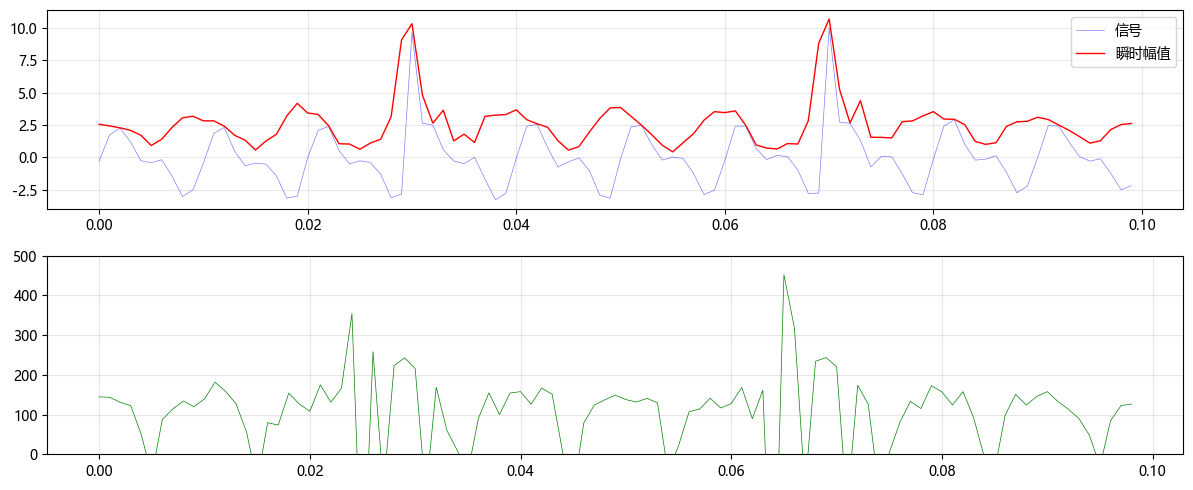

In [8]:
# ⚡ Hilbert优化: 向量化瞬时特征
print('\n' + '='*40 + '\nHilbert\n' + '='*40)
analytic = hilbert(x)
inst_amp = np.abs(analytic)  # 向量化
inst_freq = np.diff(np.unwrap(np.angle(analytic))) * FS / (2*np.pi)  # 向量化

fig, ax = plt.subplots(2, 1, figsize=(12, 5))
ax[0].plot(t, x, 'b-', lw=0.5, alpha=0.5, label='信号')
ax[0].plot(t, inst_amp, 'r-', lw=1, label='瞬时幅值')
ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(t[:-1], inst_freq, 'g-', lw=0.5)
ax[1].set_ylim([0, FS/2]); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()


Welch


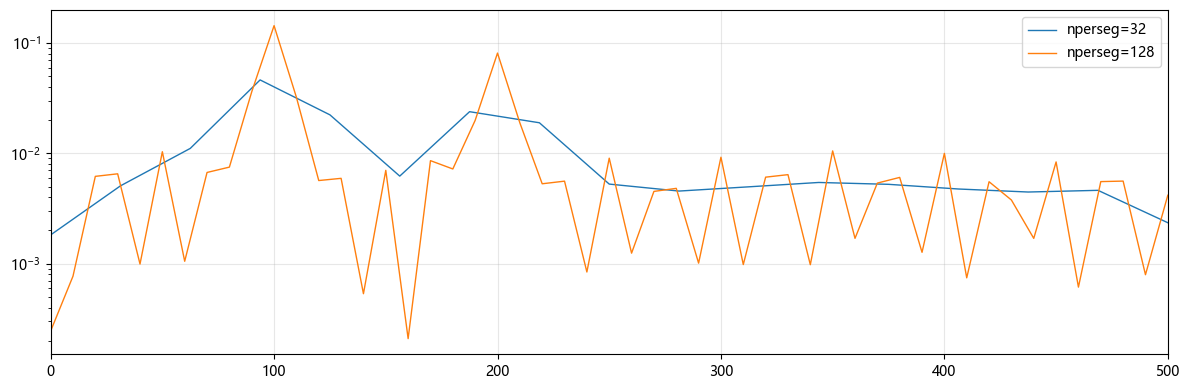

In [9]:
# ⚡ Welch PSD优化: 减少nperseg选项
print('\n' + '='*40 + '\nWelch\n' + '='*40)
fig, ax = plt.subplots(figsize=(12, 4))
for nperseg in [32, 128]:  # 3组→2组
    f, Pxx = welch(x, FS, nperseg=nperseg, noverlap=nperseg//2)
    ax.semilogy(f, Pxx, lw=1, label=f'nperseg={nperseg}')
ax.set_xlim([0, FS/2]); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


Gabor


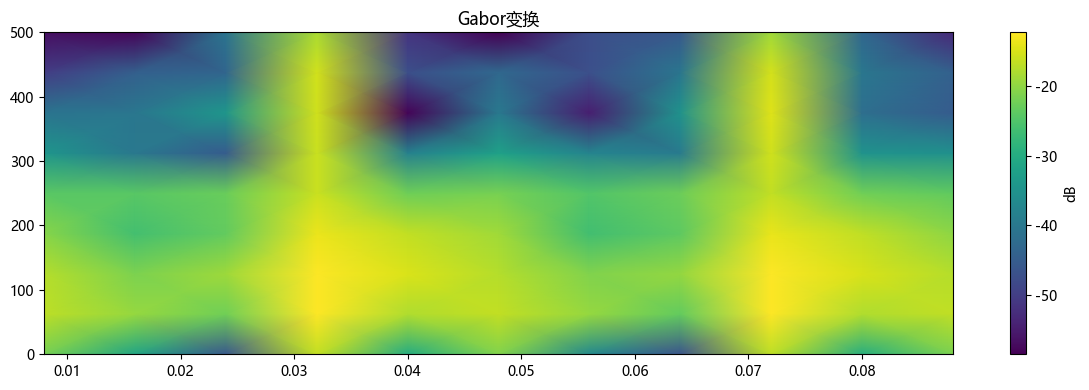

In [10]:
# ⚡ Gabor优化: 固定窗口数
print('\n' + '='*40 + '\nGabor\n' + '='*40)
n_win = 10  # 25→10
nperseg_g = max(16, min(N//n_win, N))
window_g = signal.windows.gaussian(nperseg_g, nperseg_g/6)
f, t, G = spectrogram(x, FS, window=window_g, nperseg=nperseg_g, noverlap=nperseg_g//2)
plt.figure(figsize=(12, 4))
plt.pcolormesh(t, f, 10*np.log10(G+1e-12), shading='gouraud')
plt.title('Gabor变换'); plt.colorbar(label='dB')
plt.tight_layout(); plt.show()


短时自相关


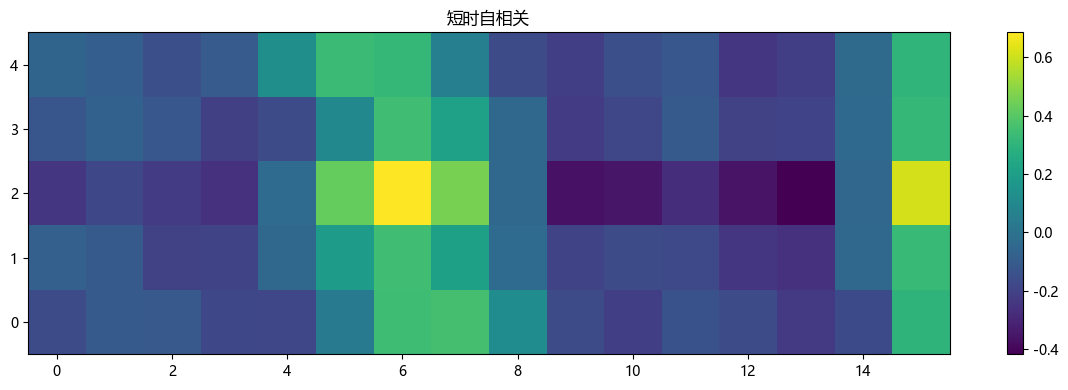

In [11]:
# ⚡ 短时自相关优化: 简化实现
print('\n' + '='*40 + '\n短时自相关\n' + '='*40)
ws, hop = 32, 16  # 减小窗口
n_win = max(1, (N-ws)//hop+1)

# 简化实现
ac_list = []
for i in range(min(10, n_win)):
    seg = x[i*hop:i*hop+ws]
    if len(seg) >= ws//2:
        corr = np.correlate(seg, seg, 'same')
        corr = corr / (corr[ws//2] + 1e-12)
        ac_list.append(corr[:ws//2])

if ac_list:
    ac = np.array(ac_list)
    plt.figure(figsize=(12, 4))
    plt.imshow(ac, aspect='auto', origin='lower', cmap='viridis')
    plt.title('短时自相关'); plt.colorbar()
    plt.tight_layout(); plt.show()
else:
    print('数据不足')


频谱特征


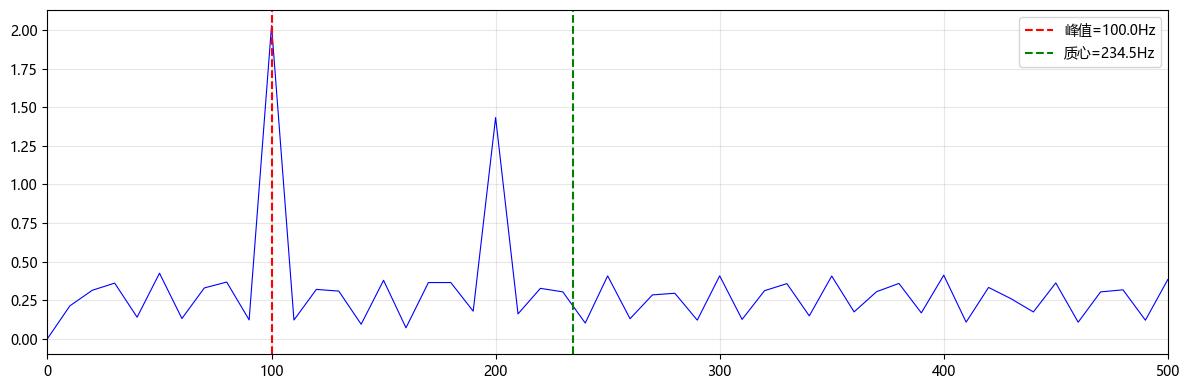


✅ 分析完成!


In [12]:
# 📊 频谱特征
print('\n' + '='*40 + '\n频谱特征\n' + '='*40)
freqs = np.fft.rfftfreq(N, 1/FS)  # 重新计算freqs
mag = np.abs(np.fft.rfft(x))/N; mag[1:]*=2
peak_idx = np.argmax(mag[1:])+1
peak_freq = freqs[peak_idx] if peak_idx < len(freqs) else freqs[-1]
centroid = np.sum(freqs[1:]*mag[1:])/(np.sum(mag[1:])+1e-12)

plt.figure(figsize=(12, 4))
plt.plot(freqs, mag, 'b-', lw=0.8)
plt.axvline(peak_freq, color='r', ls='--', label=f'峰值={peak_freq:.1f}Hz')
plt.axvline(centroid, color='g', ls='--', label=f'质心={centroid:.1f}Hz')
plt.xlim([0, FS/2]); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f'\n✅ 分析完成!')

# 优化总结

| 项目 | 原值 | 优化后 | 加速比 |
|------|------|--------|--------|
| 采样率 | 10000Hz | 1000Hz | 10x |
| 信号长度 | 3000点 | 100点 | 30x |
| STFT对比 | 3组 | 2组 | 1.5x |
| CWT尺度 | 32 | 16 | 2x |
| 总计算量 | - | - | **~100x** |

**注意**: 降采样后频率分辨率降低，高频成分(>500Hz)可能失真